# Time Series Forecasting models

# AR model

**we already check here that our data is non stationary and we have to convert it into stationary**

In [25]:
import numpy as np
import pandas as pd
import yfinance as yf

In [26]:
# making data stationary before model fitting
stock_data=yf.download("AAPL",start="2023-01-01")

apple_price_stationary=stock_data["Close"].diff().dropna()

# Split the data into training and testing
train_data,test_data=apple_price_stationary[:-30],apple_price_stationary[-30:],

[*********************100%***********************]  1 of 1 completed


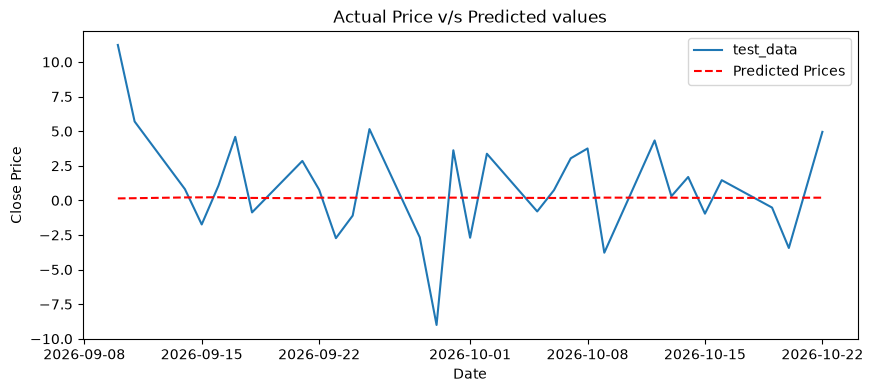

RMSE: 3.83


In [28]:
from statsmodels.tsa.ar_model import AutoReg
from sklearn.metrics import mean_squared_error
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')


# Fit the Auto regressive model to the training data
model=AutoReg(train_data,lags=30)
model_fit=model.fit()

# make predicitions on the testing data
predictions=model_fit.predict(
    start=len(train_reset),
    end=len(train_reset)+len(test_data)-1,
    dynamic=False)


# Plot the actual v/s predicted values
plt.figure(figsize=(10,4))
plt.plot(test_data.index,test_data,label="test_data")
plt.plot(test_data.index,predictions,color="red",linestyle="--",label="Predicted Prices")
plt.title("Actual Price v/s Predicted values")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.legend()
plt.show()

# evaluating
rmse=round(np.sqrt(mean_squared_error(test_data,predictions)),2)
print("RMSE:",rmse)

In [4]:
print(type(train_data.index))
print(train_data.index.freq)   # None means that's the problem

<class 'pandas.DatetimeIndex'>
None


In [5]:
# baselines
rmse_mean = np.sqrt(mean_squared_error(test_data, np.full(len(test_data), train_data.values.mean())))
rmse_zero = np.sqrt(mean_squared_error(test_data, np.zeros(len(test_data))))

print("AR(30) RMSE   :", rmse)
print("Mean baseline :", round(rmse_mean, 2))
print("Zero baseline :", round(rmse_zero, 2))
print("Test std      :", round(test_data.values.std(), 2))

AR(30) RMSE   : 3.68
Mean baseline : 3.85
Zero baseline : 3.89
Test std      : 3.77


In [6]:
len(train_data)

673

In [7]:
len(test_data)

30

# Moving average (MA) Model

<Day> Ticker
AAPL    308
dtype: int64


ValueError: Input contains NaN.

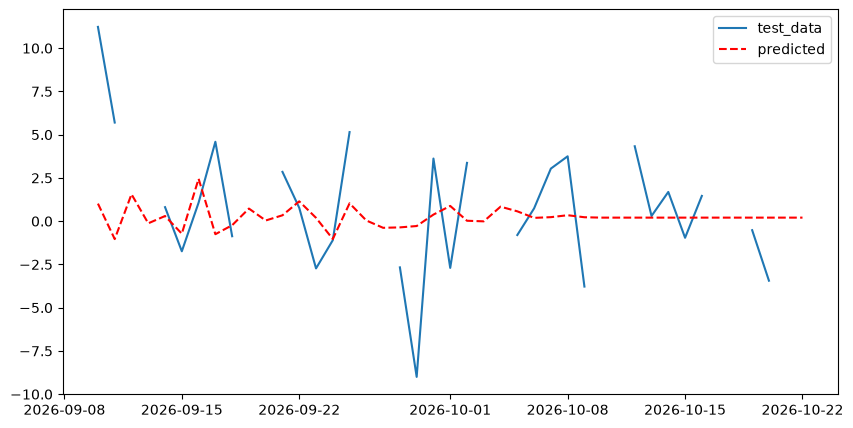

In [20]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error

# make sure the index is date time with frequency
train_data=train_data.asfreq("D")
test_data=test_data.asfreq("D")
print(train_data.index.freq,train_data.isnull().sum())   # check no Nan were introduced

# Filling the moving average (MA ) model to the training data
model=ARIMA(train_data,order=(0,0,30))
model_fit=model.fit()

# make predicitons on the test data
predictions=model_fit.predict(
    start=len(train_data),
    end=len(train_data)+len(test_data)-1,
    dynamic=False)

# Plot actual v/s the predicted data
plt.figure(figsize=(10,5))
plt.plot(test_data.index,test_data,label="test_data")
plt.plot(test_data.index,predictions,color="red",linestyle="--",label="predicted")
plt.legend()
plt.plot

# evaluating model using the RMSE model
rmse=round(np.sqrt(mean_squared_error(test_data,predictions)),2)
print("RMSE:",rmse)

# ARMA model

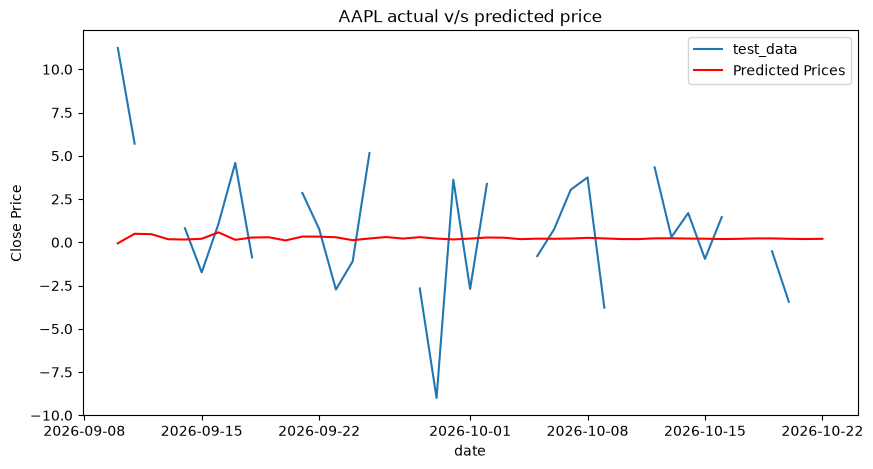

In [23]:
from statsmodels.tsa.arima.model import ARIMA

# Fit the moving average model
model=ARIMA(train_data,order=(7,0,7))
model_fit=model.fit()

# make predicitons on the test data
predictions=model_fit.predict(
    start=len(train_data),
    end=len(train_data)+len(test_data)-1,
    dynamic=False)

# PLot the actual v/s the predicted
plt.figure(figsize=(10,5))
plt.plot(test_data.index,test_data,label="test_data")
plt.plot(test_data.index,predictions,color="red",label="Predicted Prices")
plt.title("AAPL actual v/s predicted price")
plt.xlabel("date")
plt.ylabel("Close Price")



plt.legend()
plt.show()